# Semantic Segmentation on PASCAL VOC 2012
U-Net-style decoder on a frozen MobileNetV2 encoder, evaluated with mIoU on the official VOC val set.

## Setup

In [12]:
import os, random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
import kagglehub
from tensorflow.keras import layers

In [14]:
IMG_SIZE = 256
NUM_CLASSES = 21     # background + 20 object classes
IGNORE_LABEL = 255
SEED = 42
BATCH_SIZE = 32
CLASS_NAMES = ["background", "aeroplane", "bicycle", "bird", "boat", "bottle", "bus",
               "car", "cat", "chair", "cow", "diningtable", "dog", "horse", "motorbike",
               "person", "pottedplant", "sheep", "sofa", "train", "tvmonitor"]
EPOCHS = 50
tf.keras.utils.set_random_seed(SEED)

In [5]:
path = kagglehub.dataset_download("huanghanchina/pascal-voc-2012")
VOC_DIR = os.path.join(path, "VOC2012")
print("Data at:", VOC_DIR)

Using Colab cache for faster access to the 'pascal-voc-2012' dataset.
Data at: /kaggle/input/pascal-voc-2012/VOC2012


## Data

In [6]:
def read_ids(split_name):
    with open(os.path.join(VOC_DIR, "ImageSets", "Segmentation", split_name + ".txt")) as f:
        return f.read().split()

test_ids = read_ids("val")

train_pool = read_ids("train")
random.Random(SEED).shuffle(train_pool)
n_val = int(0.15 * len(train_pool))
val_ids, train_ids = train_pool[:n_val], train_pool[n_val:]

print(f"train: {len(train_ids)}  val: {len(val_ids)}  test: {len(test_ids)}")
assert not set(train_ids) & set(val_ids)
assert not set(train_ids) & set(test_ids)

train: 1245  val: 219  test: 1449


In [7]:
def load_split(ids):
    images, masks = [], []
    for i in ids:
        img = Image.open(os.path.join(VOC_DIR, "JPEGImages", i + ".jpg")).convert("RGB")
        mask = Image.open(os.path.join(VOC_DIR, "SegmentationClass", i + ".png"))
        images.append(np.array(img.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)))
        masks.append(np.array(mask.resize((IMG_SIZE, IMG_SIZE), Image.NEAREST)))
    return np.stack(images), np.stack(masks)

x_train, y_train = load_split(train_ids)
x_val, y_val = load_split(val_ids)
x_test, y_test = load_split(test_ids)

print(x_train.shape, y_train.shape, x_train.dtype, y_train.dtype)
print("mask values:", np.unique(y_train))

(1245, 256, 256, 3) (1245, 256, 256) uint8 uint8
mask values: [  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20 255]


In [9]:
def preprocess(image, mask):
    image = tf.keras.applications.mobilenet_v2.preprocess_input(tf.cast(image, tf.float32))
    return image, mask

def augment(image, mask):
    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_left_right(image)
        mask = tf.image.flip_left_right(mask[..., None])[..., 0]
    return image, mask

def make_dataset(x, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if training:
        ds = ds.shuffle(len(x), seed=SEED).map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(x_train, y_train, training=True)
val_ds = make_dataset(x_val, y_val)
test_ds = make_dataset(x_test, y_test)

images, masks = next(iter(train_ds))
print(images.shape, masks.shape, float(tf.reduce_min(images)), float(tf.reduce_max(images)))

(32, 256, 256, 3) (32, 256, 256) -1.0 1.0


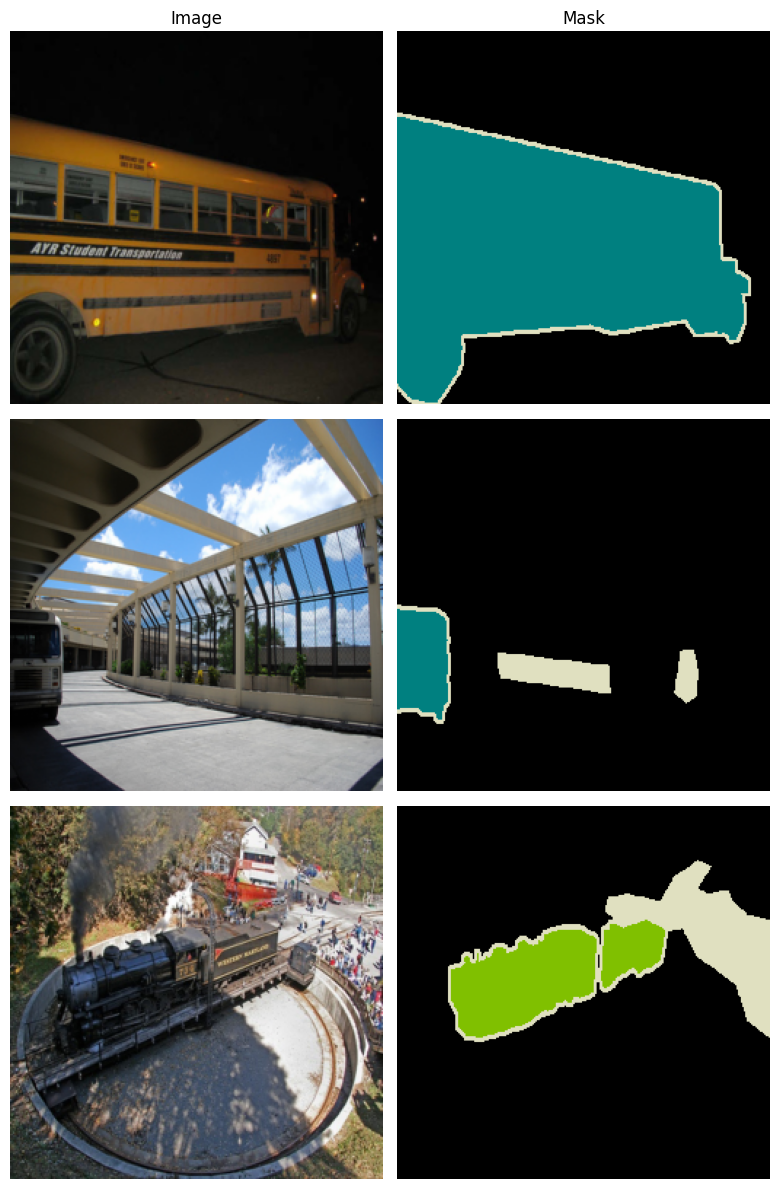

In [16]:
def voc_colormap(n=256):
    cmap = np.zeros((n, 3), dtype=np.uint8)
    for i in range(n):
        c, r, g, b = i, 0, 0, 0
        for j in range(8):
            r |= ((c >> 0) & 1) << (7 - j)
            g |= ((c >> 1) & 1) << (7 - j)
            b |= ((c >> 2) & 1) << (7 - j)
            c >>= 3
        cmap[i] = [r, g, b]
    return cmap

COLORMAP = voc_colormap()

def show(rows, titles, save_as=None):
    fig, axes = plt.subplots(len(rows), len(titles),
                             figsize=(4 * len(titles), 4 * len(rows)), squeeze=False)
    for r, row in enumerate(rows):
        for c, img in enumerate(row):
            axes[r, c].imshow(img)
            axes[r, c].axis("off")
            if r == 0:
                axes[r, c].set_title(titles[c])
    plt.tight_layout()
    if save_as:
        plt.savefig(save_as, dpi=100, bbox_inches="tight")
    plt.show()

idx = np.random.RandomState(SEED).choice(len(x_train), 3, replace=False)
show([[x_train[i], COLORMAP[y_train[i]]] for i in idx], ["Image", "Mask"])

## Model

In [13]:
def build_model(dropout_rate=0.3):
    base = tf.keras.applications.MobileNetV2(
        input_shape=[IMG_SIZE, IMG_SIZE, 3], include_top=False, weights="imagenet")
    skip_names = ["block_1_expand_relu", "block_3_expand_relu",
                  "block_6_expand_relu", "block_13_expand_relu", "block_16_project"]
    encoder = tf.keras.Model(base.input, [base.get_layer(n).output for n in skip_names])
    encoder.trainable = False

    inputs = tf.keras.Input(shape=[IMG_SIZE, IMG_SIZE, 3])
    *skips, x = encoder(inputs, training=False)

    for filters, skip in zip([320, 96, 32, 24], reversed(skips)):
        x = layers.UpSampling2D(2, interpolation="bilinear")(x)
        skip = layers.Conv2D(filters, 1, padding="same")(skip)
        x = layers.Concatenate()([x, skip])
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.Dropout(dropout_rate)(x)

    x = layers.UpSampling2D(2, interpolation="bilinear")(x)
    outputs = layers.Conv2D(NUM_CLASSES, 1, activation="softmax")(x)
    return tf.keras.Model(inputs, outputs)

model = build_model()
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(ignore_class=IGNORE_LABEL),
    metrics=[tf.keras.metrics.MeanIoU(num_classes=NUM_CLASSES, sparse_y_pred=False,
                                      ignore_class=IGNORE_LABEL, name="miou")],
)
model.summary()

/tmp/ipykernel_1450/2028605952.py:2: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ functional          │ [(None, 128, 128, │  1,841,984 │ input_layer_1[0]… │
│ (Functional)        │ 96), (None, 64,   │            │                   │
│                     │ 64, 144), (None,  │            │                   │
│                     │ 32, 32, 192),     │            │                   │
│                     │ (None, 16, 16,    │            │                   │
│                     │ 576), (None, 8,   │            │                   │
│                     │ 8, 320)]          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 16, 16,    │          0 │ functional[0][4]  │
│ (UpSampling2D)      │ 320)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 16, 16,    │    184,640 │ functional[0][3]  │
│                     │ 320)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 16, 16,    │          0 │ up_sampling2d[0]… │
│ (Concatenate)       │ 640)              │            │ conv2d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 16, 16,    │  1,843,520 │ concatenate[0][0] │
│                     │ 320)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 16, 16,    │          0 │ conv2d_1[0][0]    │
│                     │ 320)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_1     │ (None, 32, 32,    │          0 │ dropout[0][0]     │
│ (UpSampling2D)      │ 320)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 32, 32,    │     18,528 │ functional[0][2]  │
│                     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 32, 32,    │          0 │ up_sampling2d_1[… │
│ (Concatenate)       │ 416)              │            │ conv2d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 32, 32,    │    359,520 │ concatenate_1[0]… │
│                     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32, 32,    │          0 │ conv2d_3[0][0]    │
│                     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_2     │ (None, 64, 64,    │          0 │ dropout_1[0][0]   │
│ (UpSampling2D)      │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │      4,640 │ functional[0][1]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 64, 64,    │          0 │ up_sampling2d_2[… │
│ (Concatenate)       │ 128)              │            │ conv2d_4[0][0]  

 Total params: 4,304,701 (16.42 MB)

 Trainable params: 2,462,717 (9.39 MB)

 Non-trainable params: 1,841,984 (7.03 MB)

## Training

In [15]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint("best_model.keras", monitor="val_miou",
                                       mode="max", save_best_only=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_miou", mode="max",
                                         factor=0.5, patience=4, min_lr=1e-6),
    tf.keras.callbacks.EarlyStopping(monitor="val_miou", mode="max",
                                     patience=10, restore_best_weights=True),
]

history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks)

Epoch 1/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 89s 1s/step - loss: 1.6619 - miou: 0.0365 - val_loss: 1.0887 - val_miou: 0.0468 - learning_rate: 1.0000e-04
Epoch 2/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 10s 243ms/step - loss: 1.1707 - miou: 0.0555 - val_loss: 0.9146 - val_miou: 0.0753 - learning_rate: 1.0000e-04
Epoch 3/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 10s 246ms/step - loss: 1.0352 - miou: 0.0866 - val_loss: 0.8005 - val_miou: 0.1260 - learning_rate: 1.0000e-04
Epoch 4/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 9s 241ms/step - loss: 0.9191 - miou: 0.1242 - val_loss: 0.7201 - val_miou: 0.1572 - learning_rate: 1.0000e-04
Epoch 5/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 10s 247ms/step - loss: 0.8274 - miou: 0.1583 - val_loss: 0.6477 - val_miou: 0.1926 - learning_rate: 1.0000e-04
Epoch 6/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 9s 237ms/step - loss: 0.7640 - miou: 0.1890 - val_loss: 0.6077 - val_miou: 0.2309 - learning_rate: 1.0000e-04
Epoch 7/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 9s 234ms/step - loss: 0.7370 - miou: 0.2120 - val_loss: 0.5881 - val_miou

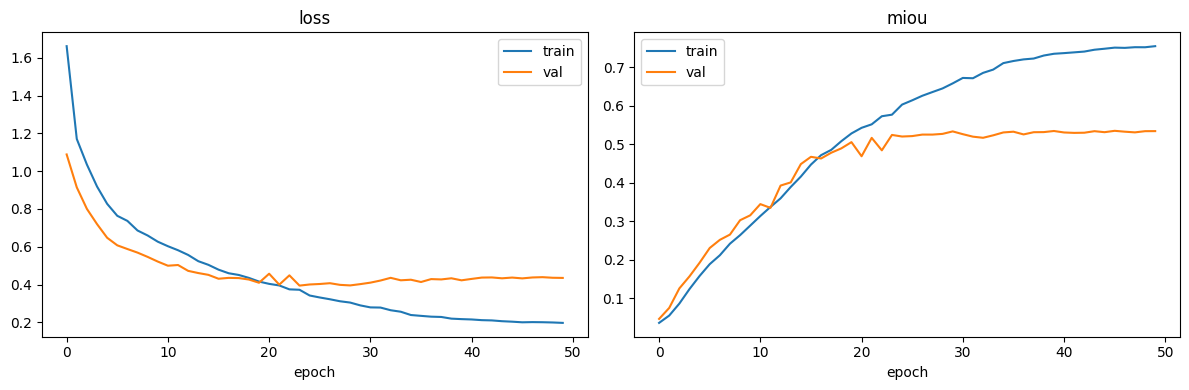

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, key in zip(axes, ["loss", "miou"]):
    ax.plot(history.history[key], label="train")
    ax.plot(history.history["val_" + key], label="val")
    ax.set_title(key)
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.savefig("training_curves.png", dpi=100)
plt.show()

## Evaluation

In [18]:
conf = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
for images, masks in test_ds:
    preds = tf.argmax(model(images, training=False), axis=-1).numpy().ravel()
    true = masks.numpy().ravel().astype(np.int64)
    valid = true != IGNORE_LABEL
    conf += np.bincount(NUM_CLASSES * true[valid] + preds[valid],
                        minlength=NUM_CLASSES ** 2).reshape(NUM_CLASSES, NUM_CLASSES)

iou = np.diag(conf) / (conf.sum(0) + conf.sum(1) - np.diag(conf))
pixel_acc = np.diag(conf).sum() / conf.sum()

print(f"Test mIoU: {iou.mean():.4f}   Pixel accuracy: {pixel_acc:.4f}\n")
for name, v in sorted(zip(CLASS_NAMES, iou), key=lambda t: -t[1]):
    print(f"{name:<12} {v:.3f}")

Test mIoU: 0.5650   Pixel accuracy: 0.8917

background   0.895
bus          0.734
car          0.706
aeroplane    0.706
person       0.688
cat          0.688
bird         0.645
motorbike    0.637
dog          0.630
train        0.627
sheep        0.606
tvmonitor    0.588
boat         0.580
bottle       0.563
cow          0.500
horse        0.471
diningtable  0.420
bicycle      0.394
pottedplant  0.327
sofa         0.278
chair        0.182


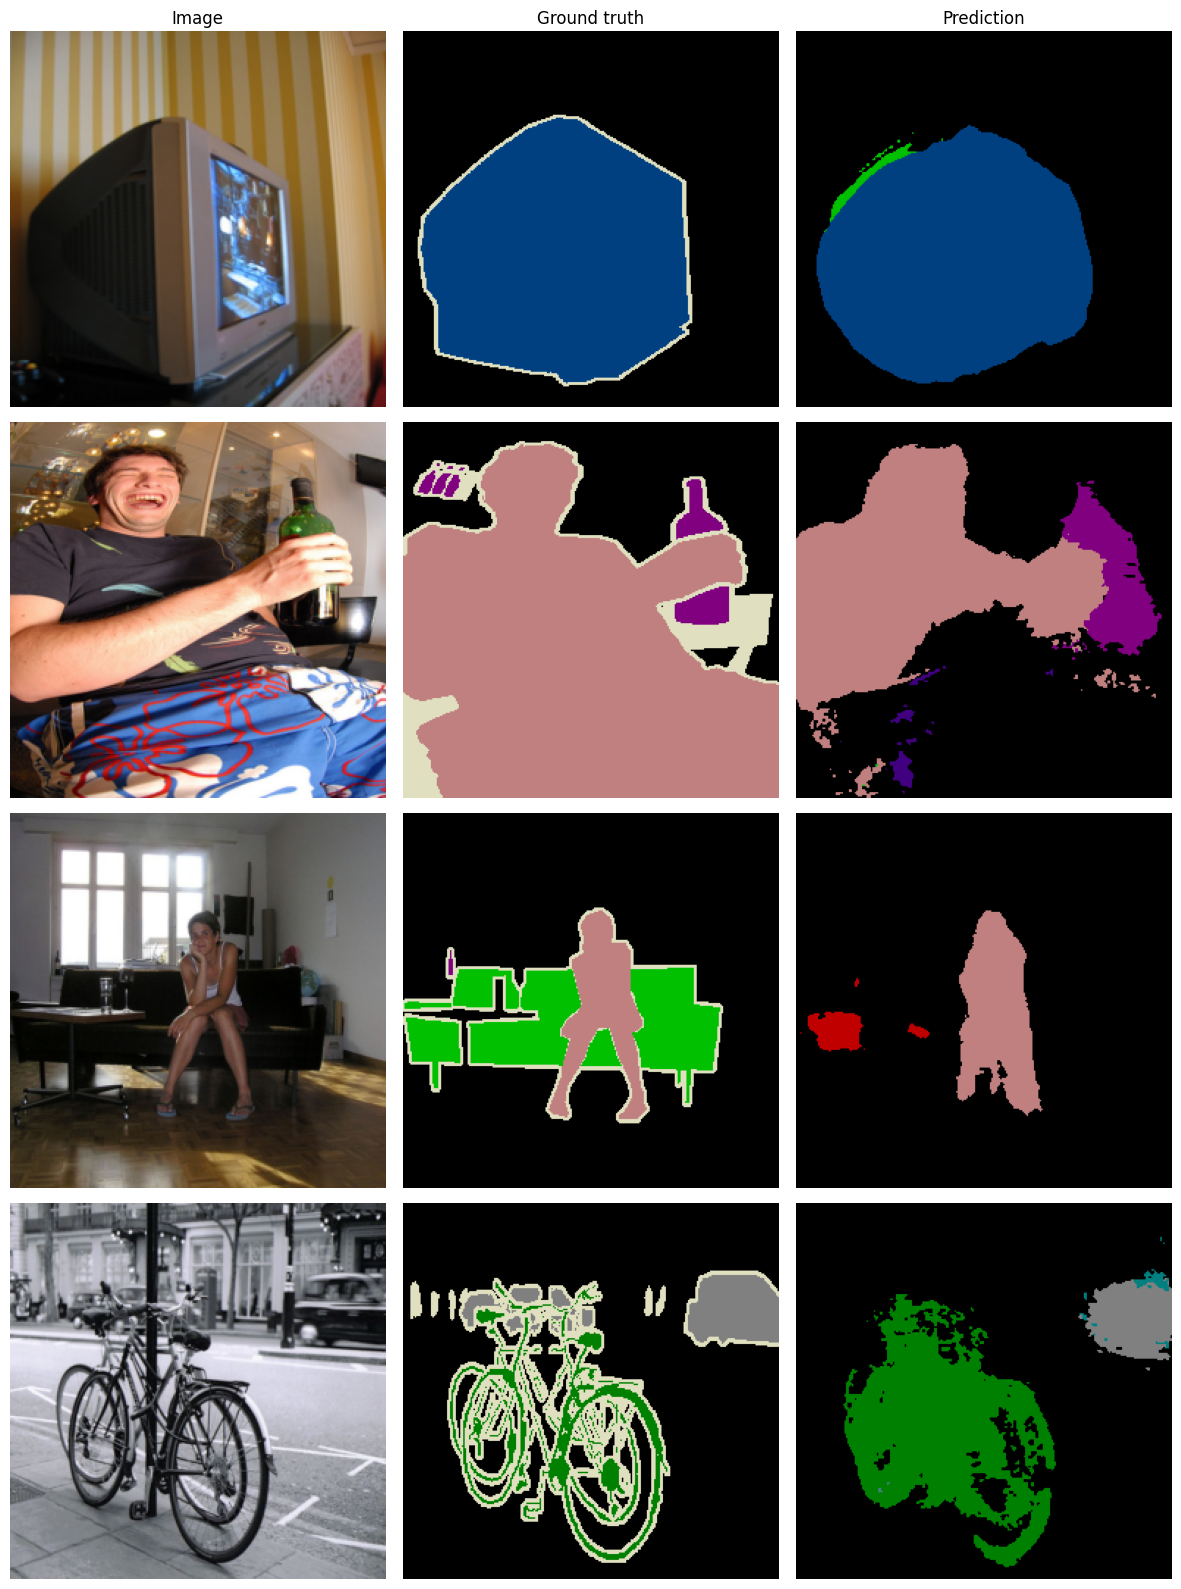

In [19]:
idx = np.random.RandomState(SEED).choice(len(x_test), 4, replace=False)
inputs = tf.keras.applications.mobilenet_v2.preprocess_input(x_test[idx].astype("float32"))
preds = np.argmax(model.predict(inputs, verbose=0), axis=-1)

show([[x_test[i], COLORMAP[y_test[i]], COLORMAP[p]] for i, p in zip(idx, preds)],
     ["Image", "Ground truth", "Prediction"], save_as="predictions.png")

## Save

In [21]:
from google.colab import files
for f in ["best_model.keras", "training_curves.png", "predictions.png"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>